# NUMPY ADVANCED 

## Numpy array vs Python list


### SPEED

In [1]:
# speed
# list
a = [i for i in range(10000000)]
b = [i for i in range(10000000,20000000)]

c = []
import time 

start = time.time()
for i in range(len(a)):
  c.append(a[i] + b[i])
print(time.time()-start)

1.8127460479736328


In [2]:
# numpy
import numpy as np
a = np.arange(10000000)
b = np.arange(10000000,20000000)

start = time.time()
c = a + b
print(time.time()-start)

0.1222684383392334


In [4]:
1.8127/0.1222
# ALMOST 15 TIMES FASTER

14.833878887070377

### MEMORY

In [5]:
# memory
a = [i for i in range(10000000)]
import sys

sys.getsizeof(a)

89095160

In [6]:
a = np.arange(10000000,dtype=np.int8)
sys.getsizeof(a)

10000112

## ADVANCED INDEXING 

### FANCY INDEXING 

In [13]:
a1=np.arange(24).reshape(6,4)
print(a1)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]


In [14]:
# Fancy indexing 
a1[[0,1,3,5]]


array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [12, 13, 14, 15],
       [20, 21, 22, 23]])

In [15]:
a1[:,[0,1,3]]

array([[ 0,  1,  3],
       [ 4,  5,  7],
       [ 8,  9, 11],
       [12, 13, 15],
       [16, 17, 19],
       [20, 21, 23]])

### BOOLEAN INDEXING 

In [ ]:
# genrating random integrs using randint function 
a2=np.random.randint(1,100,24).reshape(6,4)
print(a2)

[[80 22 56 11]
 [87 24 61 60]
 [ 7 37 69 82]
 [48 50 91 59]
 [83 81 13 32]
 [25 98 22 65]]


In [21]:
# finding all the numbers in 2d array greater than 50 
a2[a2>50]

array([80, 56, 87, 61, 60, 69, 82, 91, 59, 83, 81, 98, 65], dtype=int32)

In [22]:
# finding all the even numbers 
a2[a2%2==0]

array([80, 22, 56, 24, 60, 82, 48, 50, 32, 98, 22], dtype=int32)

In [23]:
# finding all the elements greater than 50 and are even 
a2[(a2>50)&(a2%2==0)]

array([80, 56, 60, 82, 98], dtype=int32)

In [24]:
# finding all the elements not divisibel by 7
a2[a2%7!=0]

array([80, 22, 11, 87, 24, 61, 60, 37, 69, 82, 48, 50, 59, 83, 81, 13, 32,
       25, 22, 65], dtype=int32)

## BROADCASTING

The term broadcasting describes how NumPy treats arrays with different shapes during arithmetic operations.
The smaller array is “broadcast” across the larger array so that they have compatible shapes.



In [25]:
# same shape
a = np.arange(6).reshape(2,3)
b = np.arange(6,12).reshape(2,3)

print(a)
print(b)

print(a+b)

[[0 1 2]
 [3 4 5]]
[[ 6  7  8]
 [ 9 10 11]]
[[ 6  8 10]
 [12 14 16]]


In [27]:
# diff shape
a = np.arange(6).reshape(2,3)
b = np.arange(3).reshape(1,3)

print(a)
print(b)
# addition possible even of different shape

print(a+b)

[[0 1 2]
 [3 4 5]]
[[0 1 2]]
[[0 2 4]
 [3 5 7]]


### Broadcasting Rules
1. Make the two arrays have the same number of dimensions.
   If the numbers of dimensions of the two arrays are different, add new dimensions with size 1 to the head of the array with the smaller dimension.
2. Make each dimension of the two arrays the same size.
   If the sizes of each dimension of the two arrays do not match, dimensions with size 1 are stretched to the size of the other array.
   If there is a dimension whose size is not 1 in either of the two arrays, it cannot be broadcasted, and an error is raised.

   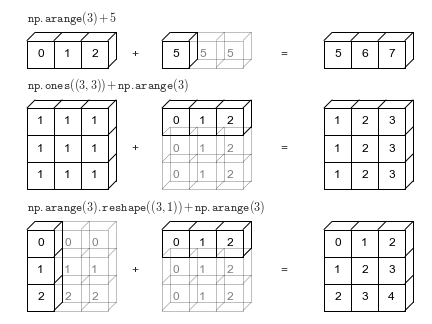

In [ ]:
# More example 
a=np.arange(12).reshape(3,4)
b=np.arange(3)
print(a)
print(b)

# print(a+b) NOT POSSIBLE AS BROADCASTING IS NOT POSSIBLE


In [ ]:
#  more example
a=np.arange(12).reshape(4,3)
b=np.arange(3)
print(a)
print(b)

# NOW THE BROADCASTING IS POSSIBLE 
# it adds b to each and every row 
print(a+b)

[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]
[0 1 2]
[[ 0  2  4]
 [ 3  5  7]
 [ 6  8 10]
 [ 9 11 13]]


In [35]:

a = np.arange(16).reshape(4,4)
b = np.array([[10]])  # Shape is (1, 1) - just 1 element!

print(a + b)

[[10 11 12 13]
 [14 15 16 17]
 [18 19 20 21]
 [22 23 24 25]]


## WORKING WITH MATHEMATICAL FORMUALAE


### SIGMOID

In [36]:
def sigmoid(array):
    return 1/(1+np.exp(-(array)))

a=np.arange(5)
sigmoid(a)


array([0.5       , 0.73105858, 0.88079708, 0.95257413, 0.98201379])

### MEAN SQUARED ERROR (loss function of linear regression)

In [37]:
# Mean squared error
actual = np.random.randint(1,50,25)
predicted = np.random.randint(1,50,25)
print("actual=",actual)
print("predicted=",predicted)

actual= [36  5  2 36 32 10 42 20 49  3 30 41  2  6  7  9 10 46 44 24 29  5 27 20
 33]
predicted= [33 11 10 17 26 46 25 37 31 16  6 41 23 40 48 49 49 47 20  2 35 42 21  9
 45]


In [ ]:
# mean squared error loss fucntion
def mse(actual,predicted):
    return np.mean((actual-predicted)**2)

mse(actual,predicted)

np.float64(504.6)

## WORKING WITH MISSING VALUES 

In [40]:
# when there are missing values 
a=np.array([1,2,3,4,np.nan,6])
print(a)

[ 1.  2.  3.  4. nan  6.]


In [41]:
np.isnan(a)

array([False, False, False, False,  True, False])

In [49]:
a[~np.isnan(a)].astype(int)


array([1, 2, 3, 4, 6])

## PLOTTING GARPHS

In [ ]:
# Plotting a graph
# x=y
x=np.linspace()